In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

# X: Ingreso medio (median_income)
# Y: Valor medio de la vivienda (median_house_value) - lo dividimos entre 100,000 para manejar una escala limpia
X = df['median_income'].values[:50]
Y = (df['median_house_value'].values[:50]) / 100000.0

print(f"Datos cargados: {len(X)} viviendas de California analizadas.")

Datos cargados: 50 viviendas de California analizadas.


In [4]:
w = 0.0  
b = 0.0  

# Hiperparámetros
learning_rate = 0.01  
epochs = 2000         
n = len(X)

historial_costos = []

# 3. Se entrenan los datos (Descenso del Gradiente)
for epoch in range(epochs):
    Y_pred = w * X + b
    
    # MSE
    cost = (1 / (2 * n)) * np.sum((Y_pred - Y) ** 2)
    historial_costos.append(cost)
    
    # Gradientes
    dw = (2 / n) * np.sum((Y_pred - Y) * X)
    db = (2 / n) * np.sum(Y_pred - Y)
    
    # Actualización de pesos
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("¡Entrenamiento completado!")
print(f"Ecuación final aprendida: Y = {w:.4f} * X + {b:.4f}")

¡Entrenamiento completado!
Ecuación final aprendida: Y = 0.4416 * X + 0.6011


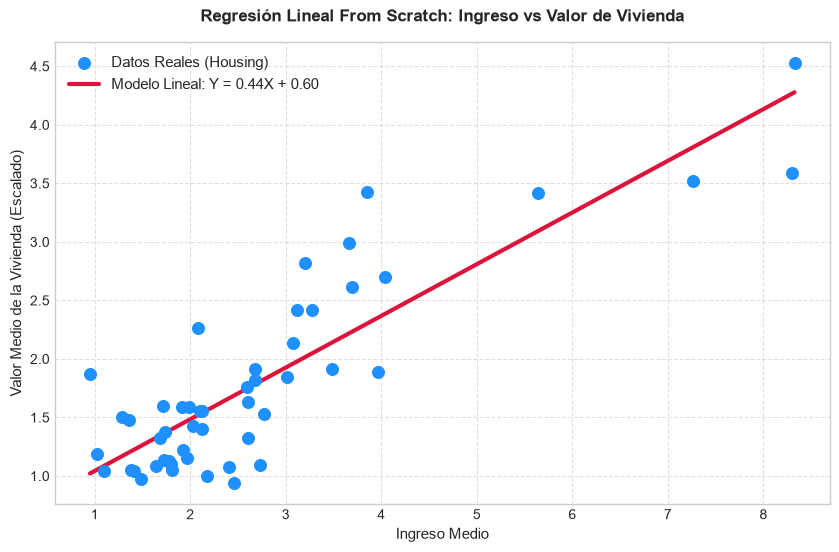

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(X, Y, color='dodgerblue', s=70, label='Datos Reales (Housing)', zorder=5)

X_linea = np.linspace(min(X), max(X), 100)
Y_linea = w * X_linea + b
plt.plot(X_linea, Y_linea, color='crimson', linewidth=3, label=f'Modelo Lineal: Y = {w:.2f}X + {b:.2f}')

plt.title('Regresión Lineal From Scratch: Ingreso vs Valor de Vivienda', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ingreso Medio', fontsize=11)
plt.ylabel('Valor Medio de la Vivienda (Escalado)', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()